# 03 - Modelagem e validação

**Abordagem:**
- **Baseline:** Regressão Logística com `class_weight="balanced"` e features padronizadas.
- **Modelo avançado:** XGBoost com `scale_pos_weight` (trata o desbalanceamento 16% de churn).
- **Validação:** CV estratificada de 5 folds + holdout (20%).
- **Métricas prioritárias:** PR-AUC, Recall, F1 — **não** acurácia (classe rara + decisão
  financeira depende de precision/recall na região de risco).


In [1]:
%matplotlib inline
import sys, pathlib, os
ROOT = pathlib.Path(os.getcwd())
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

import features as fe
import business as bz
import train as T

RAW = ROOT / "data" / "raw" / "BankChurners.csv"
ART = ROOT / "artifacts"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


In [2]:
raw = T.load_raw(RAW)
X, feature_columns = fe.build_features(raw)
y = (raw[fe.TARGET_COLUMN].astype(str).str.strip() == fe.TARGET_POSITIVE).astype(int).reset_index(drop=True)
X = X.reset_index(drop=True)

# CV estratificada — comparativo Logística vs. XGBoost
cv_lr = T.cv_evaluate(T.make_logreg, X, y)
cv_xgb = T.cv_evaluate(T.make_xgb, X, y)

res = pd.DataFrame({
    "Logistica (baseline)": cv_lr.drop(columns="fold").mean(),
    "XGBoost (scale_pos_weight)": cv_xgb.drop(columns="fold").mean(),
}).T[["pr_auc", "roc_auc", "recall_at_0.5", "precision_at_0.5", "f1", "recall_at_0.3"]]
res.round(4)


,pr_auc,roc_auc,recall_at_0.5,precision_at_0.5,f1,recall_at_0.3
Logistica (baseline),0.7739,0.9400,0.8715,0.5554,0.6781,0.9330
XGBoost (scale_pos_weight),0.9712,0.9935,0.9213,0.9071,0.9141,0.9441


In [3]:
# Holdout com modelo final treinado (artifacts/churn_model.pkl)
from sklearn.model_selection import train_test_split
import json, joblib

X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
medians = json.loads((ART / "medians.json").read_text())
model = joblib.load(ART / "churn_model.pkl")

scores = T.churn_proba(model, fe.impute_medians(X_hold, medians))
hold_metrics = T.evaluate(y_hold.to_numpy(), scores)
pd.Series(hold_metrics).round(4)


pr_auc              0.9687
roc_auc             0.9931
precision_at_0.5    0.9012
recall_at_0.5       0.8985
f1                  0.8998
recall_at_0.3       0.9354
precision_at_0.3    0.8492
dtype: float64

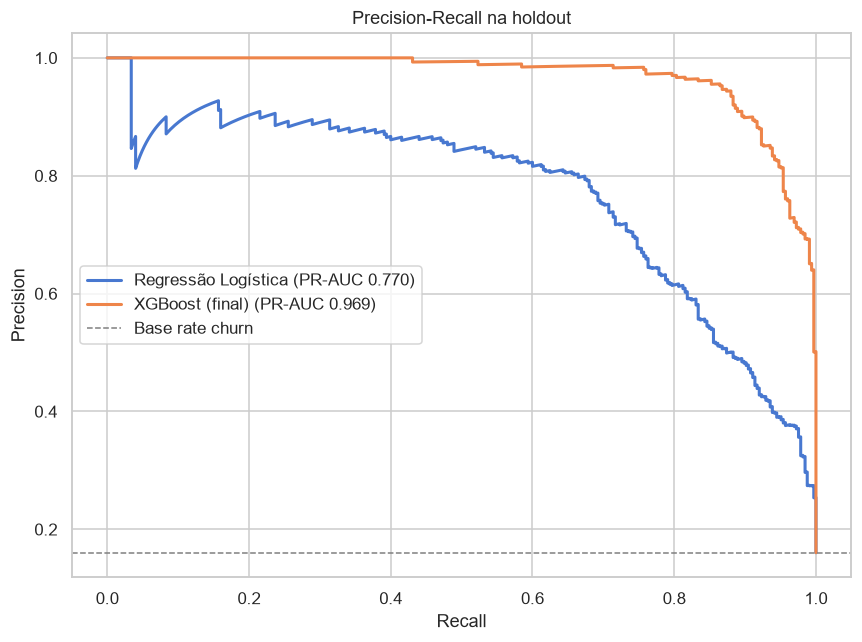

In [4]:
# Curva Precision-Recall: Logística vs. XGBoost tunado (holdout)
from sklearn.metrics import precision_recall_curve, average_precision_score

lr = T.make_logreg(X_train, y_train)
lr.fit(fe.impute_medians(X_train, medians), y_train)
scores_lr = T.churn_proba(lr, fe.impute_medians(X_hold, medians))

fig, ax = plt.subplots(figsize=(8, 6))
for name, s in [("Regressão Logística", scores_lr), ("XGBoost (final)", scores)]:
    prec, rec, _ = precision_recall_curve(y_hold.to_numpy(), s)
    ap = average_precision_score(y_hold.to_numpy(), s)
    ax.plot(rec, prec, label=f"{name} (PR-AUC {ap:.3f})", lw=2)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall na holdout")
ax.axhline(y_hold.mean(), color="gray", ls="--", lw=1, label="Base rate churn")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "pr_curve.png", bbox_inches="tight")
plt.show()


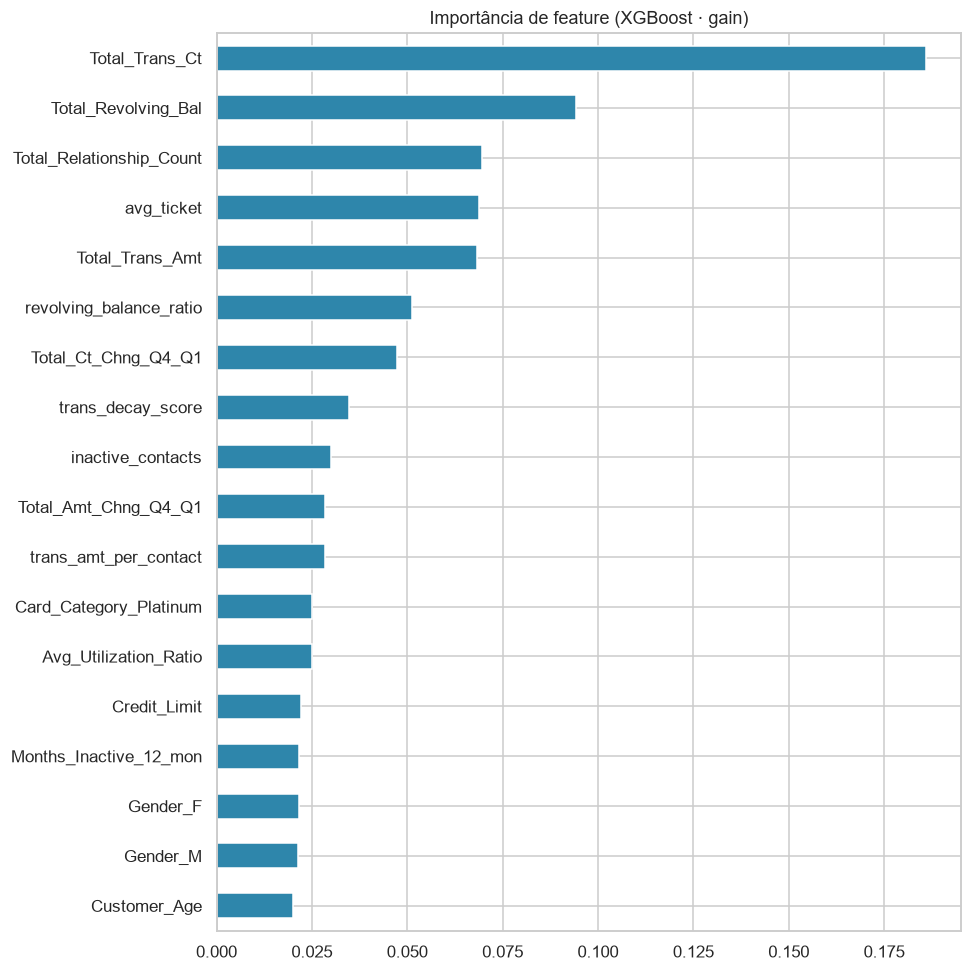

In [5]:
# Importância de feature do XGBoost (gain)
imp = pd.Series(model.feature_importances_, index=feature_columns).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 9))
imp.tail(18).plot.barh(ax=ax, color="#2e86ab")
ax.set_title("Importância de feature (XGBoost · gain)")
plt.tight_layout()
plt.savefig(FIG / "feature_importance.png", bbox_inches="tight")
plt.show()


### Resultado

| Modelo | PR-AUC (CV) | Recall@0.5 | F1 (CV) |
|---|---|---|---|
| Regressão Logística | ~0.77 | 0.87 | 0.68 |
| XGBoost | ~0.97 | 0.92 | 0.92 |
| XGBoost tunado (holdout) | ~0.97 | 0.89 | 0.90 |

O XGBoost domina a logística na região de interesse. `Months_Inactive_12_mon`, `Contacts_Count_12_mon`,
`Total_Trans_Amt/Ct` e `Avg_Utilization_Ratio` são os sinais mais fortes — coerentes com a EDA.
Em um alerta com corte em 0,30 o recall sobe para **~0,94** (com precision ~0,86), o ponto de operação
mais adequado à retenção.
